In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

In [25]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

In [26]:
file_path = Path("C:\\Users\\dhruv\\Downloads\\juypter notebook\\advertising - Copy.csv")
df = pd.read_csv(file_path)

In [27]:
print("First 5 rows are:")
print(df.head())

First 5 rows are:
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9


In [28]:
df.shape

(200, 4)

In [29]:
df.size

800

In [30]:
df.info

<bound method DataFrame.info of         TV  Radio  Newspaper  Sales
0    230.1   37.8       69.2   22.1
1     44.5   39.3       45.1   10.4
2     17.2   45.9       69.3   12.0
3    151.5   41.3       58.5   16.5
4    180.8   10.8       58.4   17.9
..     ...    ...        ...    ...
195   38.2    3.7       13.8    7.6
196   94.2    4.9        8.1   14.0
197  177.0    9.3        6.4   14.8
198  283.6   42.0       66.2   25.5
199  232.1    8.6        8.7   18.4

[200 rows x 4 columns]>

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [32]:
print("Descriptive Statistics")
df.describe()

Descriptive Statistics


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [33]:
print(df.isnull())

df.isnull().sum()

        TV  Radio  Newspaper  Sales
0    False  False      False  False
1    False  False      False  False
2    False  False      False  False
3    False  False      False  False
4    False  False      False  False
..     ...    ...        ...    ...
195  False  False      False  False
196  False  False      False  False
197  False  False      False  False
198  False  False      False  False
199  False  False      False  False

[200 rows x 4 columns]


TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [34]:
df.dtypes

TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

In [35]:
df.corr

<bound method DataFrame.corr of         TV  Radio  Newspaper  Sales
0    230.1   37.8       69.2   22.1
1     44.5   39.3       45.1   10.4
2     17.2   45.9       69.3   12.0
3    151.5   41.3       58.5   16.5
4    180.8   10.8       58.4   17.9
..     ...    ...        ...    ...
195   38.2    3.7       13.8    7.6
196   94.2    4.9        8.1   14.0
197  177.0    9.3        6.4   14.8
198  283.6   42.0       66.2   25.5
199  232.1    8.6        8.7   18.4

[200 rows x 4 columns]>

<Axes: >

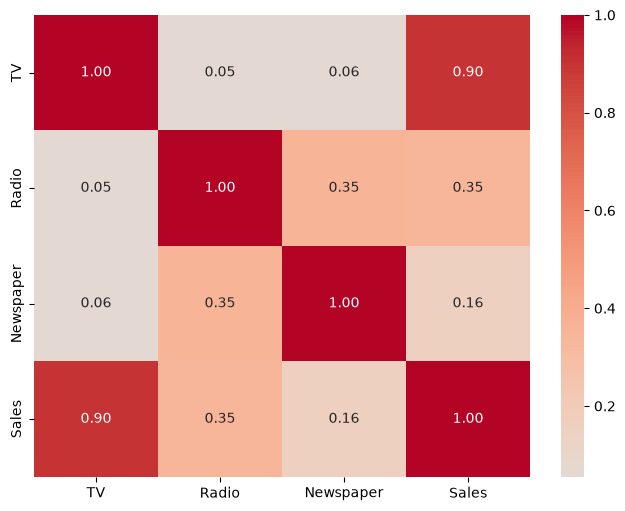

In [36]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')

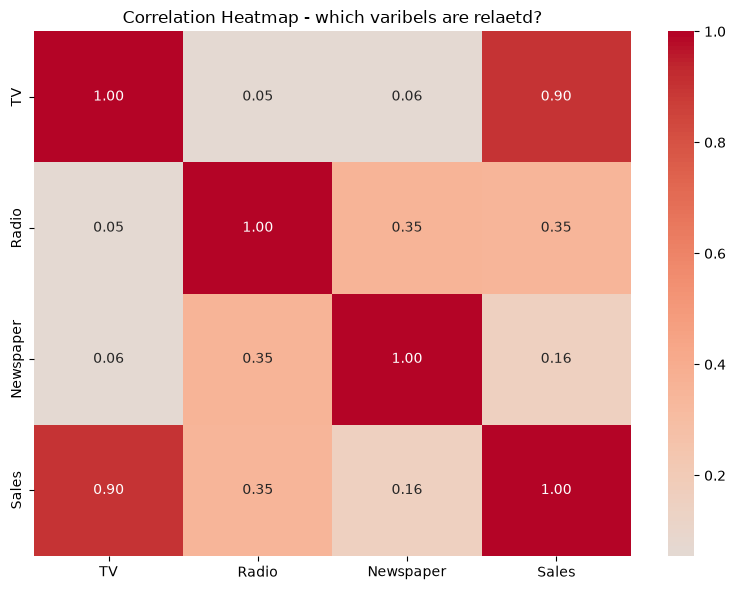

In [37]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Heatmap - which varibels are relaetd?')
plt.tight_layout()
plt.show()

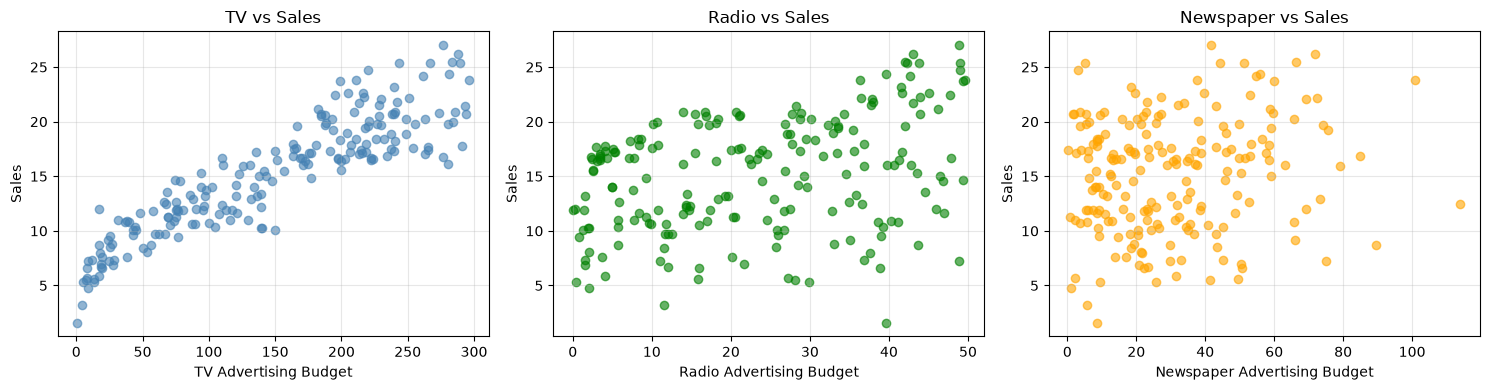

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
 
# Create scatter plot for TV vs Sales
axes[0].scatter(df['TV'], df['Sales'], alpha=0.6, color='steelblue')
axes[0].set_xlabel('TV Advertising Budget')
axes[0].set_ylabel('Sales')
axes[0].set_title('TV vs Sales')
axes[0].grid(True, alpha=0.3)
 
# Create scatter plot for Radio vs Sales
axes[1].scatter(df['Radio'], df['Sales'], alpha=0.6, color='green')
axes[1].set_xlabel('Radio Advertising Budget')
axes[1].set_ylabel('Sales')
axes[1].set_title('Radio vs Sales')
axes[1].grid(True, alpha=0.3)
 
# Create scatter plot for Newspaper vs Sales
axes[2].scatter(df['Newspaper'], df['Sales'], alpha=0.6, color='orange')
axes[2].set_xlabel('Newspaper Advertising Budget')
axes[2].set_ylabel('Sales')
axes[2].set_title('Newspaper vs Sales')
axes[2].grid(True, alpha=0.3)
 
plt.tight_layout()
plt.show()

In [39]:
X=df[["TV","Radio","Newspaper"]]
y=df.Sales


print("\nFirst 5 values of X (TV):")
print(X.head())
 
print("\nFirst 5 values of y (Sales):")
print(y.head())

X (TV) shape: (200, 3)
y (Sales) shape: (200,)

First 5 values of X (TV):
      TV  Radio  Newspaper
0  230.1   37.8       69.2
1   44.5   39.3       45.1
2   17.2   45.9       69.3
3  151.5   41.3       58.5
4  180.8   10.8       58.4

First 5 values of y (Sales):
0    22.1
1    10.4
2    12.0
3    16.5
4    17.9
Name: Sales, dtype: float64


In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [41]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(160, 3)
(40, 3)
(160,)
(40,)


In [46]:
X_train_sm = sm.add_constant(X_train)

In [47]:
X_train_sm.head()

,const,TV,Radio,Newspaper
79,1.0,116.0,7.7,23.1
197,1.0,177.0,9.3,6.4
38,1.0,43.1,26.7,35.1
24,1.0,62.3,12.6,18.3
122,1.0,224.0,2.4,15.6


In [48]:
lr= sm.OLS(y_train,X_train_sm).fit()

In [49]:
lr.params 

const        4.714126
TV           0.054509
Radio        0.100945
Newspaper    0.004337
dtype: float64

In [50]:
#y=m1x1+m2x2+m3x3+c
#y= 0.054509*TV+0.100945*Radio+0.004337*Newspaper+4.714126

In [1]:
# as an example let's say we spend 10 unit TV,Radio,Newspaper how much sales will i get.
#0.054509*10+0.100945*10+0.004337*10+4.714126
0.54509 + 1.00945 + 0.04337 + 4.714126

6.312036

In [52]:
#Sales=6.3

In [53]:
lr.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.900
Model:                            OLS   Adj. R-squared:                  0.898
Method:                 Least Squares   F-statistic:                     468.7
Date:                Wed, 23 Sep 2026   Prob (F-statistic):           8.51e-78
Time:                        18:13:48   Log-Likelihood:                -305.78
No. Observations:                 160   AIC:                             619.6
Df Residuals:                     156   BIC:                             631.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.7141      0.352     13.407      0.000       4.020       5.409
TV             0.0545      0.002     34.972      0.000       0.051       0.058
Radio          0.1009      0.010     10.470      0.000       0.082       0.120
Newspaper      0.0043      0.007      0.619      0.537      -0.010       0.018
==============================================================================
Omnibus:                       13.344   Durbin-Watson:                   2.108
Prob(Omnibus):                  0.001   Jarque-Bera (JB):               22.080
Skew:                          -0.422   Prob(JB):                     1.60e-05
Kurtosis:                       4.613   Cond. No.                         471.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
plt.scatter(X_train,y_train)
plt.plot(X_train,0.*X_train+4.334596)
plt.plot()